# STA4020 Part 1 · Return Model and Fixed Asset Universe

## 摘要

**2014 年 12 月 30 日一次锁定 50 支。** 对当时符合资格的 2,178 支沪深 A 股预测下一月收益，按预测从高到低取前 50。训练标签最晚到 2014 年 11 月 28 日，OOS 建仓是 12 月 31 日。独立核验将数值输入截断在锁池日，重新生成的 50 个 ticker、排序和预测值一致。

**样本外跑赢了两个市场参照。** 2015 年 1 月至 2024 年 8 月共 116 个月。固定池内按预测配置前 25 支，计入交易成本后年化 **15.07%**。同期中证 500 价格指数 **−1.41%**，FF5 广义市场代理 **2.02%**，相同交易假设下的固定池等权 **6.97%**。模型组合最大回撤 **−51.36%**。

先用 OOS 前的数据和模型一次性锁定 50 支股票，再在固定池内更新预期收益和组合权重。

## 1. 固定池与样本外协议

| 时点 | 允许做什么 |
|---|---|
| **截至 2014-12-30 收盘** | 用宽截面的沪深 A 股估计模型和预测 2015 年 1 月收益。训练标签最晚到 2014-11-28。用预测值从高到低排一次，取前 50 名并锁定。 |
| **2014-12-31 收盘** | 首次按模型权重模拟建仓。OOS 从这个收盘时点开始。 |
| **2015-01 至 2024-08** | 每月以当时已知数据预测同一批 50 支股票，更新池内权重。停牌、交易限制或缺少信号影响可下单数量，资产池成员及入池排名始终固定。 |

**锁池规则。** 在信号日有报价、过去 12 个完整月有收益、有上月市值且当天可交易的股票进入评分范围。按过去 72 个已成熟的训练截面做因子筛选和岭回归。用 2014-12-30 的特征计算次月预期收益并排序。分数相同按 ticker 排序。此后任意月份的表现、数据覆盖和指数成分变化都不参与这 50 支的选择。

**预测规则。** 用日度、周度和月度收益构造特征，统一预测次月简单总收益。滚动训练每次只使用信号日以前已经结束的标签。已成熟的 OOS 标签随后可以进入训练窗，以模拟按月重估，冻结的 50 支维持原样。

**权重规则。** 每次在固定池中对有信号的股票按预测排序，前 25 支预设各占 4%，其余为 0。遇到信号不足、无法交易或资金受限时，剩余金额计入现金。多头股票与现金的权重之和始终为 1。以固定池的等权组合作为归因对照，使用一致的执行和成本假设。

In [1]:
# Install the notebook dependencies from the project requirements.txt.
from pathlib import Path

import h5py
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import brentq
from scipy.stats import spearmanr

PROJECT = Path(".") if Path("notebooks/Part1_Return_Model.ipynb").is_file() else Path("..")
DATA = PROJECT / "data"
OUTPUT = PROJECT / "part1_output"

FIRST_OOS_TARGET = pd.Period("2015-01", freq="M")
TRAIN_MONTHS = 72
RISK_MONTHS = 36
POOL_SIZE = 50
MODEL_HOLDINGS = 25
TRADE_COST_RATE = 0.0020  # Per yuan of stock bought or sold (20 bps)
assert 31 <= POOL_SIZE and 1 <= MODEL_HOLDINGS <= POOL_SIZE
MIN_FACTOR_PAIRS = 100
MIN_IC_MONTHS = 48
RIDGE_PENALTY = 0.10
FF5_PREMIUM_SHRINK = 0.50
FDR_Q = 0.10
MAX_EXTRA_FACTORS = 5
BLOCK_MONTHS = 6
BOOTSTRAPS = 1999
SEED = 4020

CORE_FACTORS = [
    "log_size", "log_amount_21d", "volatility_63d",
    "momentum_8w", "momentum_12_1m", "return_month_to_signal",
]
MAIN = "IC + FM ridge"
CORE = "Core FM ridge"
HIST = "Historical mean"
FF5 = "FF5 risk premia"
BASE = "Historical universe mean"
MODELS = [MAIN, CORE, HIST, FF5, BASE]

plt.rcParams.update({
    "figure.dpi": 135,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.22,
    "font.size": 10,
})

## 2. 原始数据与时点

| 文件 | 本实验用法 |
|---|---|
| `monthly_returns.pkl` | 月收益标签、月频价格信号及风险模型输入。收益单位为小数。 |
| `price.h5` | 日度复权收盘价、实际交易日历以及周频收益。价格缺口保留。 |
| `mcap.pkl` | 上一日历月末的市值。只要求正值，并将其作为风险与收益特征。 |
| `daily_amount.pkl` | 过去 21 个交易日的平均成交额。统一 XSHE/XSHG 和 SZ/SH 后连接。 |
| `BLACKLIST.pkl`、`UNTRADABLE.pkl` | 逐日状态记录。信号日用于资格约束，随后月末交易日的记录只约束当日模拟成交，不改变预测、排名或固定池名单。 |
| `FF5.csv`、`risk_free.csv` | 五因子风险溢价模型。用 MKT + 月度 RF 作为广义市场收益代理。 |
| `zz500.pk` | 中证 500 价格指数文件，取与股票回测完全对齐的月末交易日收盘价。 |

数据口径参考项目的 `instruction.txt` 和 `return_model_content/`。财务披露时间和历史版本未知，因此本实验用可定时的市场特征。文件中的退市收益、停牌缺失及数据商历史修订仍可能影响测量。

In [2]:
def month_index(frame):
    frame = frame.copy()
    frame.index = pd.DatetimeIndex(frame.index).to_period("M")
    frame = frame.sort_index()
    assert frame.index.is_unique and frame.columns.is_unique
    return frame


def month_end(period):
    return period.end_time.normalize()


raw_returns = month_index(pd.read_pickle(DATA / "monthly_returns.pkl"))
market_cap = month_index(pd.read_pickle(DATA / "mcap.pkl"))
first_formation = FIRST_OOS_TARGET - 1
first_feature_month = first_formation - (TRAIN_MONTHS + 1)
last_target = raw_returns.index.max()
formation_months = pd.period_range(first_feature_month, last_target - 1, freq="M")
oos_months = formation_months[formation_months >= first_formation]
assert len(oos_months) >= 60
assert last_target >= FIRST_OOS_TARGET + 59
assert raw_returns.index.equals(pd.period_range(raw_returns.index[0], last_target, freq="M"))

with h5py.File(DATA / "price.h5", "r") as price_file:
    store = price_file["price"]
    trading_days = pd.DatetimeIndex(store["axis1"][:])
    price_columns = pd.Index(store["axis0"].asstr()[:], name="Asset")
    assert price_columns.equals(pd.Index(store["block0_items"].asstr()[:]))
    assert trading_days.is_unique and trading_days.is_monotonic_increasing
    start = trading_days.searchsorted((first_feature_month - 5).start_time)
    finish = trading_days.searchsorted(last_target.end_time, side="right")
    prices = pd.DataFrame(
        store["block0_values"][start:finish], index=trading_days[start:finish],
        columns=price_columns,
    )

assets = prices.columns.intersection(raw_returns.columns).sort_values()
assets = assets[assets.str.fullmatch(r"\d{6}\.(SZ|SH)")]
prices = prices.reindex(columns=assets).where(lambda values: values.gt(0))
returns = raw_returns.reindex(columns=assets).replace([np.inf, -np.inf], np.nan)
market_cap = market_cap.reindex(columns=assets)
assert (returns.stack() >= -1).all()

exchange_month = pd.Series(prices.index, index=prices.index).groupby(prices.index.to_period("M"))
last_close = exchange_month.last()
signal_close = exchange_month.nth(-2)
signal_close.index = signal_close.index.to_period("M")
assert (signal_close.reindex(formation_months) < last_close.reindex(formation_months)).all()

# Cross-check close-to-close return construction on all overlapping quotes.
end_prices = prices.loc[last_close.to_numpy()].set_axis(last_close.index)
implied_monthly = end_prices.pct_change(fill_method=None)
price_difference = (implied_monthly - returns.reindex(implied_monthly.index)).abs().stack()
assert price_difference.size > 100_000
display(pd.Series({
    "Shanghai / Shenzhen symbols in raw data": len(assets),
    "Overlapping price/return observations": price_difference.size,
    "Share matching to 1 bp": price_difference.le(0.0001).mean(),
    "First OOS target month": str(FIRST_OOS_TARGET),
    "Last OOS target month": str(last_target),
    "OOS target months": len(oos_months),
}, name="Source and calendar checks").to_frame())

,Source and calendar checks
Shanghai / Shenzhen symbols in raw data,5377
Overlapping price/return observations,584040
Share matching to 1 bp,1.0
First OOS target month,2015-01
Last OOS target month,2024-08
OOS target months,116


In [3]:
def restrictions_on_days(filename, days):
    records = pd.read_pickle(DATA / filename).index
    dates = records.get_level_values("date")
    selected = records[dates.isin(days)]
    return {
        pd.Timestamp(date): pd.Index(rows.index.get_level_values("asset").unique())
        for date, rows in selected.to_frame(index=True).groupby(level="date", sort=False)
    }


def load_daily_amount(days, asset_columns):
    amount = pd.read_pickle(DATA / "daily_amount.pkl")["total_turnover"]
    date_level = amount.index.levels[1]
    keep = date_level.isin(days)[amount.index.codes[1]]
    wide = amount.loc[keep].unstack("order_book_id")
    wide.columns = (
        wide.columns.str.replace(".XSHE", ".SZ", regex=False)
        .str.replace(".XSHG", ".SH", regex=False)
    )
    assert wide.index.is_unique and wide.columns.is_unique
    return wide.reindex(index=days, columns=asset_columns).astype("float32")


audit_days = pd.Index(signal_close.reindex(formation_months)).union(
    pd.Index(last_close.reindex(oos_months))
)
blacklist = restrictions_on_days("BLACKLIST.pkl", audit_days)
untradable = restrictions_on_days("UNTRADABLE.pkl", audit_days)
daily_amount = load_daily_amount(prices.index, assets)
assert daily_amount.notna().sum().sum() > 100_000

daily_returns = prices.pct_change(fill_method=None)
week_end_prices = (
    prices.loc[pd.Series(prices.index).groupby(prices.index.to_period("W-FRI")).last().to_numpy()]
    .set_axis(pd.Index(prices.index.to_period("W-FRI").unique().end_time.normalize()))
)
weekly_returns = week_end_prices.pct_change(fill_method=None)

ff5_factors = month_index(pd.read_csv(DATA / "FF5.csv", index_col="date", parse_dates=True))
daily_rf = pd.read_csv(DATA / "risk_free.csv", index_col="date", parse_dates=True)["RF"]
assert daily_rf.index.is_unique
required_rf = daily_rf.reindex(trading_days)
required_rf = required_rf.loc[(first_feature_month - RISK_MONTHS).start_time:last_target.end_time]
assert required_rf.notna().all()
rf_monthly = (1 + required_rf).groupby(required_rf.index.to_period("M")).prod(min_count=1) - 1

display(pd.DataFrame({
    "dates": [
        f"{daily_returns.index.min():%Y-%m-%d} to {daily_returns.index.max():%Y-%m-%d}",
        f"{weekly_returns.index.min():%Y-%m-%d} to {weekly_returns.index.max():%Y-%m-%d}",
        f"{returns.index.min()} to {returns.index.max()}",
    ],
    "used for": ["5d reversal, 63d volatility", "8w momentum, 12w volatility",
                 "12–1m momentum, PCA, FF5 and next-month target"],
}, index=["Daily", "Weekly", "Monthly"]))

,dates,used for
Daily,2008-06-02 to 2024-08-30,"5d reversal, 63d volatility"
Weekly,2008-06-06 to 2024-08-30,"8w momentum, 12w volatility"
Monthly,1995-02 to 2024-08,"12–1m momentum, PCA, FF5 and next-month target"


## 3. 每月构造特征和风险因子模型

宽截面的资格检查使用信号日有效价格、交易状态、最近 12 个完整月的收益都可观测，以及正的滞后市值。每月在这个宽截面上将各特征变为中心化、单位方差量级的百分位分数。拟合时按当月截面中位数（中心分数 0）填补可选特征的缺失值。IC 用有原始特征值的样本计算。

核心特征覆盖规模、流动性、波动及不同尺度的价格趋势或反转。短期收益和周动量的方向由历史截面回归估计。

- **PCA（Lecture III）** 在截至 $t-1$ 的 36 个月上，用该窗内有完整收益且在 $t$ 可评分的股票估计收益协方差的前三个主成分。将第一主成分方向与等权市场对齐，并计算每支股票的 PC1 beta 和剔除前三个主成分后的残差波动。主成分解释的是共同变动，其预测效果由 IC 和 OOS 检验决定。
- **FF5（Lecture II）** 在过去 36 个月以 OLS 估计 $(r_{i,s}-RF_s)=\alpha_i+\beta_i^\top f_s+\epsilon_{i,s}$。预测值采用 $RF_{t-1}+\widehat\beta_i^\top(0.5\bar f)$，基于样本均值估计并收缩风险溢价，定价时设 $\alpha_i=0$。缺少完整 36 个月的股票使用市场 beta 为 1、其余暴露为 0 的回退。因子文件的实际发布版本未记录，FF5 对照假设信号日前已可取得上一个完整月的数据。

In [4]:
def pca_exposures(history):
    complete = history.dropna(axis=1)
    assert complete.shape[1] >= MIN_FACTOR_PAIRS
    centered = complete.to_numpy() - complete.to_numpy().mean(axis=0)
    variances, directions = np.linalg.eigh(centered @ centered.T)
    top = directions[:, -3:][:, ::-1]
    market_direction = centered.mean(axis=1)
    direction = top[:, 0] * (1 if top[:, 0] @ market_direction >= 0 else -1)
    # Scale PC1 to the volatility of the equal-weight reference return.
    factor = direction * np.linalg.norm(market_direction)
    loading = (factor @ centered) / (factor @ factor)
    residual = centered - top @ (top.T @ centered)
    pca_features = pd.DataFrame({
        "pc1_market_beta": loading,
        "pca_residual_volatility": residual.std(axis=0, ddof=1),
    }, index=complete.columns)
    explained = variances[-3:][::-1] / variances.sum()
    return pca_features, explained


def ff5_forecast(history):
    factors = ff5_factors.reindex(history.index)
    risk_free = rf_monthly.reindex(history.index)
    assert not factors.isna().any().any() and risk_free.notna().all()
    premium = FF5_PREMIUM_SHRINK * factors.mean().to_numpy()
    rf_forecast = risk_free.iloc[-1]
    prediction = pd.Series(rf_forecast + premium[0], index=history.columns)
    complete = history.dropna(axis=1)
    design = np.column_stack([np.ones(len(factors)), factors.to_numpy()])
    excess = complete.sub(risk_free, axis=0).to_numpy()
    slopes = np.linalg.lstsq(design, excess, rcond=None)[0][1:]
    prediction.loc[complete.columns] = rf_forecast + premium @ slopes
    return prediction, len(complete.columns) / len(history.columns)


def formation_inputs(month):
    as_of = signal_close.loc[month]
    monthly_history = returns.loc[month - RISK_MONTHS:month - 1]
    recent_amount = daily_amount.loc[:as_of].tail(21)
    previous_cap = market_cap.loc[month - 1]
    blocked = blacklist.get(as_of, pd.Index([])).union(untradable.get(as_of, pd.Index([])))
    eligible = (
        prices.loc[as_of].notna()
        & previous_cap.gt(0)
        & monthly_history.tail(12).notna().all(axis=0)
        & ~assets.isin(blocked)
    )
    eligible_assets = assets[eligible]
    assert len(eligible_assets) >= max(POOL_SIZE, MIN_FACTOR_PAIRS)
    monthly_history = monthly_history.loc[:, eligible_assets]
    pca_features, explained = pca_exposures(monthly_history)
    ff5_prediction, ff5_coverage = ff5_forecast(monthly_history)

    daily = daily_returns.loc[:as_of].tail(63).loc[:, eligible_assets]
    weekly = weekly_returns.loc[:as_of].tail(12).loc[:, eligible_assets]
    mean_amount = recent_amount.loc[:, eligible_assets].mean().where(
        recent_amount.loc[:, eligible_assets].count().ge(15)
    )
    prior_close = last_close.loc[month - 1]
    raw = pd.DataFrame({
        "log_size": np.log(previous_cap.loc[eligible_assets]),
        "log_amount_21d": np.log1p(mean_amount.where(mean_amount.ge(0))),
        "return_5d": (1 + daily.tail(5)).prod(min_count=5) - 1,
        "volatility_63d": daily.std().where(daily.count().ge(50)),
        "momentum_8w": (1 + weekly.tail(8)).prod(min_count=8) - 1,
        "volatility_12w": weekly.std().where(weekly.count().ge(10)),
        "momentum_12_1m": (1 + monthly_history.iloc[-12:-1]).prod(min_count=11) - 1,
        "lagged_month_return": monthly_history.iloc[-1],
        "return_month_to_signal": (
            prices.loc[as_of, eligible_assets] / prices.loc[prior_close, eligible_assets] - 1
        ),
    }).join(pca_features).replace([np.inf, -np.inf], np.nan)

    # Mid-rank transformation. First rank maps just above the lowest endpoint.
    ranked = raw.rank(method="average").sub(0.5).div(raw.count())
    features = (np.sqrt(12) * (ranked - 0.5)).astype("float32")
    baseline = pd.DataFrame({
        HIST: monthly_history.mean(),
        FF5: ff5_prediction,
    })
    return features, baseline, explained, ff5_coverage

## 4. 历史因子检验与截面回归

1. **Rank IC** 按月计算截面 Spearman 相关系数 $\rho_s(x_{i,t,j},r_{i,t+1})$。每个因子每月需要至少 100 个有效股票配对，每个训练窗需要至少 48 个月 IC。
ho_s(x_{i,t,j},r_{i,t+1}))。每个因子每月需要至少 100 个有效股票配对，每个训练窗需要至少 48 个月 IC。
2. **控制多重试验** 以 6 个月的循环移动块重采样各因子的月度 IC。用去均值后的重采样分布对 $E[IC]=0$ 做双侧检验。同一次重采样给所有因子使用相同的日期块，保留相关结构。Benjamini–Yekutieli 校正考虑特征间依赖。核心特征事先给定，每个训练窗中，达到 $q\le0.10$ 的非核心因子才可增补，最多增加 5 个。IC 用于筛选，方向和幅度由联合回归确定。
3. **Fama–MacBeth 风格的岭回归** 每个训练月分别回归 $r_{i,t+1}=a_t+z_{i,t}^\top b_t+\epsilon_{i,t+1}$。对该月的训练目标按 1%/99% 缩尾并对斜率加固定岭惩罚 $\lambda\lVert b_t\rVert_2^2$，其中 $\lambda=0.10$。截距不惩罚。以 72 个月系数的等权均值预测 $\widehat\mu_{i,t+1}=\bar a+z_{i,t}^\top\bar b$。固定核心模型与有 IC 增补的模型使用相同估计方式。
4. **对照** 个股历史均值取过去至多 36 个月的原始收益。历史股票截面均值以同一训练窗的原始月度截面均值等权平均，每月所有股票用同一个预测。测试收益统一保留原始值。

In [5]:
def block_draws(n_dates, seed=SEED):
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n_dates / BLOCK_MONTHS))
    starts = rng.integers(n_dates, size=(BOOTSTRAPS, n_blocks, 1))
    indices = (starts + np.arange(BLOCK_MONTHS)) % n_dates
    return indices.reshape(BOOTSTRAPS, -1)[:, :n_dates]


def by_adjust(p_values):
    valid = p_values.dropna().sort_values()
    m = len(valid)
    ranks = np.arange(1, m + 1)
    scaled = valid.to_numpy() * m * np.sum(1 / ranks) / ranks
    adjusted = np.minimum.accumulate(scaled[::-1])[::-1].clip(0, 1)
    return pd.Series(adjusted, index=valid.index).reindex(p_values.index)


def screen_factors(ic_history):
    means = ic_history.mean()
    centered = ic_history.sub(means).to_numpy()
    with np.errstate(invalid="ignore", divide="ignore"):
        samples = centered[block_draws(len(ic_history))]
        sampled_means = np.nansum(samples, axis=1) / np.isfinite(samples).sum(axis=1)
    valid_draws = np.isfinite(sampled_means).sum(axis=0)
    extreme = (np.abs(sampled_means) >= means.abs().to_numpy()).sum(axis=0)
    p_values = pd.Series((extreme + 1) / (valid_draws + 1), index=means.index)
    p_values = p_values.where(ic_history.count().ge(MIN_IC_MONTHS))
    summary = pd.DataFrame({
        "mean_rank_ic": means,
        "months": ic_history.count(),
        "p_value": p_values,
        "q_value": by_adjust(p_values),
    })
    significant_extras = summary.loc[
        summary.q_value.le(FDR_Q) & ~summary.index.isin(CORE_FACTORS)
    ].sort_values("q_value", kind="stable")
    selected = CORE_FACTORS + list(significant_extras.head(MAX_EXTRA_FACTORS).index)
    return selected, summary

In [6]:
def rank_ic(signal, target):
    measured = signal.notna() & target.notna()
    signal, target = signal.loc[measured], target.loc[measured]
    if len(signal) < MIN_FACTOR_PAIRS or signal.nunique() < 2 or target.nunique() < 2:
        return np.nan
    return float(spearmanr(signal, target).statistic)


def training_statistics(features, target):
    valid = target.notna()
    target = target.loc[valid]
    assert len(target) >= MIN_FACTOR_PAIRS
    factor_ic = features.loc[valid].apply(rank_ic, target=target)
    design = features.loc[valid].fillna(0).to_numpy(dtype=float)
    low, high = target.quantile([0.01, 0.99])
    response = target.clip(low, high).to_numpy()
    design_mean, response_mean = design.mean(axis=0), response.mean()
    centered_design, centered_response = design - design_mean, response - response_mean
    # Cache moments so different screened subsets can reuse the same monthly sample.
    return {
        "ic": factor_ic,
        "design_mean": design_mean,
        "response_mean": response_mean,
        "gram": centered_design.T @ centered_design / len(target),
        "cross": centered_design.T @ centered_response / len(target),
        "raw_return_mean": target.mean(),
    }


def fama_macbeth_ridge(train_stats, factor_names, feature_columns):
    selected = feature_columns.get_indexer(factor_names)
    assert (selected >= 0).all()
    penalty = np.eye(len(selected)) * RIDGE_PENALTY
    monthly_coefficients = []
    for stats in train_stats:
        slopes = np.linalg.solve(
            stats["gram"][np.ix_(selected, selected)] + penalty, stats["cross"][selected]
        )
        intercept = stats["response_mean"] - stats["design_mean"][selected] @ slopes
        monthly_coefficients.append(np.r_[intercept, slopes])
    return np.mean(monthly_coefficients, axis=0)

## 5. 上锁，再开始 OOS

第一次调用 `predict_month` 时，仅计算已经成熟的 72 个训练截面和建仓前的预测截面。得到排名后立刻创建固定池。后续循环按日期推进，同一批 50 支反复获得预测。暂时不在可评分截面的池成员继续留在宽表，用当期历史截面均值作预测回退，并在策略下单时跳过。

In [7]:
feature_cache = {}
training_cache = {}


def inputs_at(formation):
    if formation not in feature_cache:
        feature_cache[formation] = formation_inputs(formation)
    return feature_cache[formation]


def training_months_at(formation):
    signal_day = signal_close.loc[formation]
    matured = formation_months[
        (formation_months < formation) &
        (last_close.reindex(formation_months + 1).to_numpy() < signal_day)
    ]
    selected = matured[-TRAIN_MONTHS:]
    assert len(selected) == TRAIN_MONTHS
    assert selected.equals(pd.period_range(formation - TRAIN_MONTHS - 1, formation - 2, freq="M"))
    return selected


def predict_month(formation):
    train_months = training_months_at(formation)
    for past in train_months:
        if past not in training_cache:
            historical_features = inputs_at(past)[0]
            historical_target = returns.loc[past + 1].reindex(historical_features.index)
            training_cache[past] = training_statistics(historical_features, historical_target)

    train_stats = [training_cache[past] for past in train_months]
    ic_history = pd.DataFrame([stats["ic"] for stats in train_stats], index=train_months)
    selected, ic_audit = screen_factors(ic_history)
    features, reference, explained, _ = inputs_at(formation)
    scores = reference.copy()
    scores[BASE] = np.mean([stats["raw_return_mean"] for stats in train_stats])
    for model, columns in [(MAIN, selected), (CORE, CORE_FACTORS)]:
        coefficients = fama_macbeth_ridge(train_stats, columns, features.columns)
        scores[model] = coefficients[0] + features[columns].fillna(0) @ coefficients[1:]
    assert np.isfinite(scores[MODELS].to_numpy()).all()
    return scores[MODELS], selected, ic_audit, explained


def descending_scores(score):
    return score.sort_index().sort_values(ascending=False, kind="stable")


# Freeze once, before any OOS outcome enters training or portfolio evaluation.
oos_start = last_close.loc[first_formation]
lock_signal_date = signal_close.loc[first_formation]
first_training = training_months_at(first_formation)
initial_scores, initial_factors, initial_factor_audit, initial_pca = predict_month(first_formation)
fixed_universe = descending_scores(initial_scores[MAIN]).head(POOL_SIZE).index
last_selection_label = last_close.loc[first_training[-1] + 1]

assert tuple(training_cache) == tuple(first_training)
assert last_selection_label < lock_signal_date < oos_start
assert all(last_close.loc[past + 1] < oos_start for past in training_cache)
assert len(fixed_universe) == POOL_SIZE and fixed_universe.is_unique

locked_pool = pd.DataFrame({
    "Asset": fixed_universe,
    "Selection_Rank": np.arange(1, POOL_SIZE + 1),
    "Selection_Signal_Date": lock_signal_date,
    "OOS_Start_Close": oos_start,
    "Last_Selection_Training_Label_Date": last_selection_label,
    "Initial_Target_Date": month_end(FIRST_OOS_TARGET),
    "Initial_Expected_Return": initial_scores.loc[fixed_universe, MAIN].to_numpy(),
})
display(pd.Series({
    "Selection signal date": lock_signal_date,
    "Latest label used to select": last_selection_label,
    "OOS start close": oos_start,
    "First OOS return endpoint": last_close.loc[FIRST_OOS_TARGET],
    "First fitting window": f"{first_training[0]} through {first_training[-1]}",
    "Stocks scored at selection": len(initial_scores),
    "Fixed members": len(fixed_universe),
}, name="Pre-OOS selection audit").to_frame())
display(locked_pool[["Selection_Rank", "Asset", "Initial_Expected_Return"]].head(8))

,Pre-OOS selection audit
Selection signal date,2014-12-30 00:00:00
Latest label used to select,2014-11-28 00:00:00
OOS start close,2014-12-31 00:00:00
First OOS return endpoint,2015-01-30 00:00:00
First fitting window,2008-11 through 2014-10
Stocks scored at selection,2178
Fixed members,50


,Selection_Rank,Asset,Initial_Expected_Return
0,1,300281.SZ,0.046609
1,2,300069.SZ,0.046135
2,3,600768.SH,0.046016
3,4,600137.SH,0.045568
4,5,300277.SZ,0.044910
5,6,300354.SZ,0.044836
6,7,600355.SH,0.044680
7,8,002382.SZ,0.044576


In [8]:
fixed_forecasts = {}
signal_eligibility = {}
scored_counts = {}
factor_records = {}
pca_records = {}
for formation in oos_months:
    if formation == first_formation:
        scores, factors, explained = initial_scores, initial_factors, initial_pca
    else:
        scores, factors, _, explained = predict_month(formation)

    signal_eligibility[formation] = fixed_universe.isin(scores.index)
    # Keep all frozen members in every monthly export. For a missing signal,
    # use the common forecast in the file and mark the stock ineligible for new orders.
    stable_scores = scores.reindex(fixed_universe)
    for model in MODELS:
        stable_scores[model] = stable_scores[model].fillna(scores[BASE].iloc[0])
    fixed_forecasts[formation] = stable_scores
    scored_counts[formation] = int(signal_eligibility[formation].sum())
    factor_records[formation] = factors
    pca_records[formation] = explained

assert all(month_frame.index.equals(fixed_universe) for month_frame in fixed_forecasts.values())
assert np.isfinite(np.stack([frame.to_numpy() for frame in fixed_forecasts.values()])).all()
display(pd.Series({
    "OOS months": len(oos_months),
    "Locked members per OOS month": len(fixed_universe),
    "Minimum members with fresh signals": min(scored_counts.values()),
    "Mean members with fresh signals": np.mean(list(scored_counts.values())),
    "Fixed stock-months using fallback forecast": len(oos_months) * POOL_SIZE - sum(scored_counts.values()),
}, name="Fixed-pool coverage").to_frame())

,Fixed-pool coverage
OOS months,116.000000
Locked members per OOS month,50.000000
Minimum members with fresh signals,40.000000
Mean members with fresh signals,45.931034
Fixed stock-months using fallback forecast,472.000000


## 6. 固定池预测评估

所有模型都在同一个固定池上评估，每期取有新鲜信号且有实现收益的共同样本。Rank IC 检查股票排序，RMSE 检查预测值，OOS \(R^2\) 以个股历史均值为基准。此处截面的 50 支是 OOS 开始前冻结的，因子回归依然用每期成熟的宽截面历史估计。

In [9]:
prediction_audit = []
for formation, forecasts in fixed_forecasts.items():
    target = returns.loc[formation + 1].reindex(fixed_universe)
    common = signal_eligibility[formation] & target.notna()
    assert common.sum() >= 20
    for model in MODELS:
        estimate, realized = forecasts.loc[common, model], target.loc[common]
        ic = (
            spearmanr(estimate, realized).statistic
            if estimate.nunique() > 1 and realized.nunique() > 1 else np.nan
        )
        prediction_audit.append({
            "Target_Date": month_end(formation + 1),
            "Model": model,
            "Rank IC": ic,
            "MSE": (estimate - realized).pow(2).mean(),
        })
prediction_audit = pd.DataFrame(prediction_audit)
forecast_metrics = prediction_audit.groupby("Model")[["Rank IC", "MSE"]].mean().reindex(MODELS)
forecast_metrics["Monthly RMSE"] = np.sqrt(forecast_metrics["MSE"])
forecast_metrics["OOS R² vs historical mean"] = 1 - forecast_metrics["MSE"] / forecast_metrics.loc[HIST, "MSE"]
forecast_metrics = forecast_metrics.drop(columns="MSE")

screened_counts = pd.Series(
    [factor for selected in factor_records.values() for factor in selected]
).value_counts()
first_factor_audit = initial_factor_audit.assign(
    selected_at_lock=lambda frame: frame.index.isin(initial_factors),
    included_oos_months=lambda frame: screened_counts.reindex(frame.index, fill_value=0),
).sort_values("q_value")

display(forecast_metrics.style.format({
    "Rank IC": "{:.4f}", "Monthly RMSE": "{:.2%}", "OOS R² vs historical mean": "{:.2%}",
}, na_rep="—"))
display(first_factor_audit.style.format({
    "mean_rank_ic": "{:.4f}", "p_value": "{:.4f}", "q_value": "{:.4f}",
}))

,Rank IC,Monthly RMSE,OOS R² vs historical mean
Model,,,
IC + FM ridge,0.1463,15.83%,3.84%
Core FM ridge,0.1381,15.83%,3.77%
Historical mean,-0.0513,16.14%,0.00%
FF5 risk premia,-0.0093,15.93%,2.61%
Historical universe mean,—,15.87%,3.31%


,mean_rank_ic,months,p_value,q_value,selected_at_lock,included_oos_months
log_size,-0.0810,72,0.0005,0.0042,True,116
log_amount_21d,-0.1253,72,0.0005,0.0042,True,116
momentum_8w,-0.0591,72,0.0005,0.0042,True,116
return_month_to_signal,-0.0677,72,0.0005,0.0042,True,116
return_5d,-0.0520,72,0.0010,0.0066,True,44
pca_residual_volatility,-0.0339,72,0.0015,0.0083,True,116
volatility_63d,-0.0357,72,0.0280,0.1329,True,116
lagged_month_return,-0.0360,72,0.0320,0.1329,False,20
volatility_12w,-0.0197,72,0.1915,0.7068,False,101
momentum_12_1m,-0.0038,72,0.8260,1.0000,True,116


## 7. 样本外市场比较

**模型组合。** 信号日按次月预期收益选池内前 25 支，每支目标权重 4%。**固定池等权**给每个有信号的池成员目标权重 2%，用于衡量同一固定池里按模型调权的贡献。

模拟成交发生在月末最后交易日收盘。有价但进入黑名单的股票当天可以卖出，无法新增。不可交易或无收盘报价的仓位保持原来的金额。无法下单的配置留在现金，冻结仓位占用可投资资金时同比缩减其余买单。以买入和卖出金额各 **20 bp** 计成本，包括初次建仓。现金赚取月度无风险回报。复权收益来自原始月收益文件，源文件未注明退市清算回款，冻结持仓按该数据的实现收益记账。

**市场参照。** 主参照是 `zz500.pk` 的中证 500 收盘价，便于对照中小盘。它是价格指数口径。第二项是 `FF5.csv` 的 `MKT` 加同期 `RF`，用作广义 A 股市场收益代理。指数和市场代理按同样的月末区间复利，采用原始基准收益。参数按固定规则给定，OOS 结果只用于比较。

In [10]:
STRATEGY = f"Model top {MODEL_HOLDINGS} (net)"
POOL_EW = "Fixed pool equal weight (net)"
CSI500 = "CSI 500 price index"
MARKET_PROXY = "FF5 market + RF"

index_close = pd.read_pickle(DATA / "zz500.pk")["close"].sort_index()
assert isinstance(index_close.index, pd.DatetimeIndex)
assert index_close.index.is_unique
comparison_months = pd.period_range(first_formation, last_target, freq="M")
index_monthly = index_close.reindex(last_close.loc[comparison_months].to_numpy())
assert index_monthly.notna().all() and index_monthly.gt(0).all()
index_monthly.index = comparison_months
csi500_return = index_monthly.pct_change(fill_method=None)
broad_market_return = ff5_factors["MKT"] + rf_monthly


def execute_targets(pretrade, desired, frozen):
    # All values are fractions of pretrade NAV. Protect frozen holdings and
    # solve for fees so the post-trade stock plus cash allocation is self-financing.
    frozen_value = pretrade[frozen].sum()
    free_target = desired.mask(frozen, 0.0)
    target_total = free_target.sum()

    def stock_positions(fee):
        available = max(0.0, 1 - frozen_value - fee)
        scale = min(1.0, available / target_total) if target_total else 0.0
        return pretrade.where(frozen, free_target * scale)

    def traded_fraction(positions):
        return (positions - pretrade).abs().sum()

    fee = brentq(
        lambda estimate: estimate - TRADE_COST_RATE * traded_fraction(stock_positions(estimate)),
        0.0, 2 * TRADE_COST_RATE + 1e-10,
    )
    positions = stock_positions(fee)
    risky_weights = positions / (1 - fee)
    cash_weight = max(0.0, 1 - risky_weights.sum())
    assert risky_weights.ge(0).all()
    assert np.isclose(risky_weights.sum() + cash_weight, 1.0)
    assert np.allclose(positions[frozen], pretrade[frozen])
    return risky_weights, cash_weight, fee, traded_fraction(positions)


def actual_portfolio_return(weights, cash, realized, risk_free):
    held = weights.gt(0)
    if realized[held].isna().any():
        raise ValueError("A held fixed-universe asset has a missing realized return.")
    return float(weights[held] @ realized[held] + cash * risk_free)


pretrade = {
    STRATEGY: pd.Series(0.0, index=fixed_universe),
    POOL_EW: pd.Series(0.0, index=fixed_universe),
}
portfolio_rows = []
weight_rows = {}
for formation, forecasts in fixed_forecasts.items():
    target_month = formation + 1
    entry_day = last_close.loc[formation]
    end_day = last_close.loc[target_month]
    live_signals = fixed_universe[signal_eligibility[formation]]
    chosen = descending_scores(forecasts.loc[live_signals, MAIN]).head(MODEL_HOLDINGS).index

    frozen = prices.loc[entry_day, fixed_universe].isna()
    frozen |= fixed_universe.isin(untradable.get(entry_day, pd.Index([])))
    entry_blacklisted = fixed_universe.isin(blacklist.get(entry_day, pd.Index([])))
    realized = returns.loc[target_month, fixed_universe]
    cash_return = rf_monthly.loc[target_month]
    row = {
        "Target_Date": month_end(target_month),
        CSI500: csi500_return.loc[target_month],
        MARKET_PROXY: broad_market_return.loc[target_month],
    }
    for model, orders, total_slots in [
        (STRATEGY, chosen, MODEL_HOLDINGS),
        (POOL_EW, live_signals, POOL_SIZE),
    ]:
        desired = pd.Series(0.0, index=fixed_universe)
        desired.loc[orders] = 1 / total_slots
        desired.loc[entry_blacklisted] = 0.0
        weights, cash, fee, turnover = execute_targets(pretrade[model], desired, frozen)
        gross = actual_portfolio_return(weights, cash, realized, cash_return)
        row[model] = (1 - fee) * (1 + gross) - 1
        row[f"{model} traded fraction"] = turnover
        row[f"{model} fee"] = fee
        row[f"{model} cash"] = cash
        row[f"{model} frozen weight"] = weights[frozen].sum()
        row[f"{model} unquoted weight at endpoint"] = (
            weights[prices.loc[end_day, fixed_universe].isna()].sum()
        )
        ending_position_values = weights.mul(1 + realized).where(weights.gt(0), 0.0)
        pretrade[model] = ending_position_values / (1 + gross)
        if model == STRATEGY:
            weight_rows[entry_day] = weights.to_dict() | {"Cash": cash}
    portfolio_rows.append(row)

monthly_backtest = pd.DataFrame(portfolio_rows).set_index("Target_Date")
strategy_weights = pd.DataFrame.from_dict(weight_rows, orient="index")
strategy_weights.index.name = "Rebalance_Date"
assert strategy_weights.columns[:-1].equals(fixed_universe)
assert strategy_weights.ge(0).all().all() and np.allclose(strategy_weights.sum(axis=1), 1)
benchmarks = [STRATEGY, POOL_EW, CSI500, MARKET_PROXY]
matched_returns = monthly_backtest[benchmarks]
assert matched_returns.notna().all().all() and len(matched_returns) >= 60

In [11]:
wealth = (1 + matched_returns).cumprod()
drawdown = wealth / wealth.cummax().clip(lower=1) - 1
performance = pd.DataFrame({
    "Cumulative return": wealth.iloc[-1] - 1,
    "Annualized return": wealth.iloc[-1].pow(12 / len(wealth)) - 1,
    "Annualized volatility": matched_returns.std() * np.sqrt(12),
    "Maximum drawdown": drawdown.min(),
})
performance["Annualized return minus market proxy (pp)"] = 100 * (
    performance["Annualized return"] - performance.loc[MARKET_PROXY, "Annualized return"]
)

def block_interval(delta):
    resampled = delta.to_numpy()[block_draws(len(delta), seed=SEED + 1)]
    return np.quantile(resampled.mean(axis=1), [0.025, 0.975])


paired_differences = []
for reference in [CSI500, MARKET_PROXY, POOL_EW]:
    difference = matched_returns[STRATEGY] - matched_returns[reference]
    lower, upper = block_interval(difference)
    paired_differences.append({
        "Benchmark": reference,
        "Mean monthly spread": difference.mean(),
        "95% low": lower,
        "95% high": upper,
        "Months": len(difference),
    })
spread_results = pd.DataFrame(paired_differences).set_index("Benchmark")
execution_metrics = pd.Series({
    "Mean two-way traded fraction": monthly_backtest[f"{STRATEGY} traded fraction"].mean(),
    "Mean monthly fees as share of NAV": monthly_backtest[f"{STRATEGY} fee"].mean(),
    "Mean post-trade cash weight": monthly_backtest[f"{STRATEGY} cash"].mean(),
    "Mean frozen stock weight": monthly_backtest[f"{STRATEGY} frozen weight"].mean(),
    "Ending weight of stock positions without endpoint quotes": (
        pretrade[STRATEGY][prices.loc[last_close.loc[last_target], fixed_universe].isna()].sum()
    ),
}, name="Execution assumptions and audit")

display(performance.style.format({
    "Cumulative return": "{:.2%}", "Annualized return": "{:.2%}",
    "Annualized volatility": "{:.2%}", "Maximum drawdown": "{:.2%}",
    "Annualized return minus market proxy (pp)": "{:+.2f}",
}))
display(spread_results.style.format({
    "Mean monthly spread": "{:+.2%}", "95% low": "{:+.2%}", "95% high": "{:+.2%}",
}))
display(execution_metrics.to_frame().style.format("{:.2%}"))

,Cumulative return,Annualized return,Annualized volatility,Maximum drawdown,Annualized return minus market proxy (pp)
Model top 25 (net),288.46%,15.07%,36.19%,-51.36%,+13.05
Fixed pool equal weight (net),91.72%,6.97%,33.38%,-52.17%,+4.94
CSI 500 price index,-12.84%,-1.41%,24.46%,-58.18%,-3.43
FF5 market + RF,21.35%,2.02%,20.18%,-40.49%,+0.00


,Mean monthly spread,95% low,95% high,Months
Benchmark,,,,
CSI 500 price index,+1.55%,+0.32%,+2.90%,116
FF5 market + RF,+1.35%,-0.05%,+2.94%,116
Fixed pool equal weight (net),+0.68%,+0.30%,+1.08%,116


,Execution assumptions and audit
Mean two-way traded fraction,52.49%
Mean monthly fees as share of NAV,0.10%
Mean post-trade cash weight,0.07%
Mean frozen stock weight,4.85%
Ending weight of stock positions without endpoint quotes,0.00%


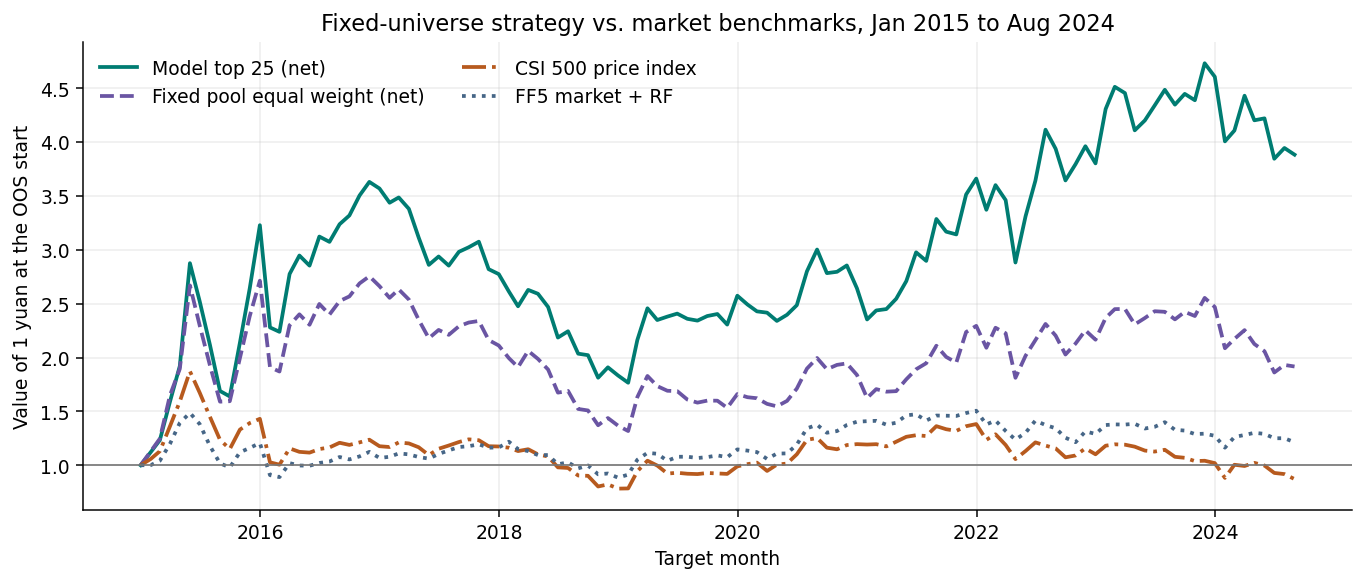

In [12]:
colors = {
    STRATEGY: "#007C72", POOL_EW: "#6A55A3", CSI500: "#B75A1E", MARKET_PROXY: "#466687",
}
styles = ["-", "--", "-.", ":"]
initial_value = pd.DataFrame(1.0, index=[oos_start], columns=wealth.columns)
plot_wealth = pd.concat([initial_value, wealth])
fig, axis = plt.subplots(figsize=(10, 4.2), layout="constrained")
for name, line_style in zip(benchmarks, styles):
    axis.plot(plot_wealth[name], label=name, color=colors[name], linestyle=line_style, lw=2.0)
axis.axhline(1, color="#777777", lw=0.9)
axis.set(title="Fixed-universe strategy vs. market benchmarks, Jan 2015 to Aug 2024",
         xlabel="Target month", ylabel="Value of 1 yuan at the OOS start")
axis.xaxis.set_major_locator(mdates.YearLocator(2))
axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axis.legend(frameon=False, ncols=2)
plt.show()

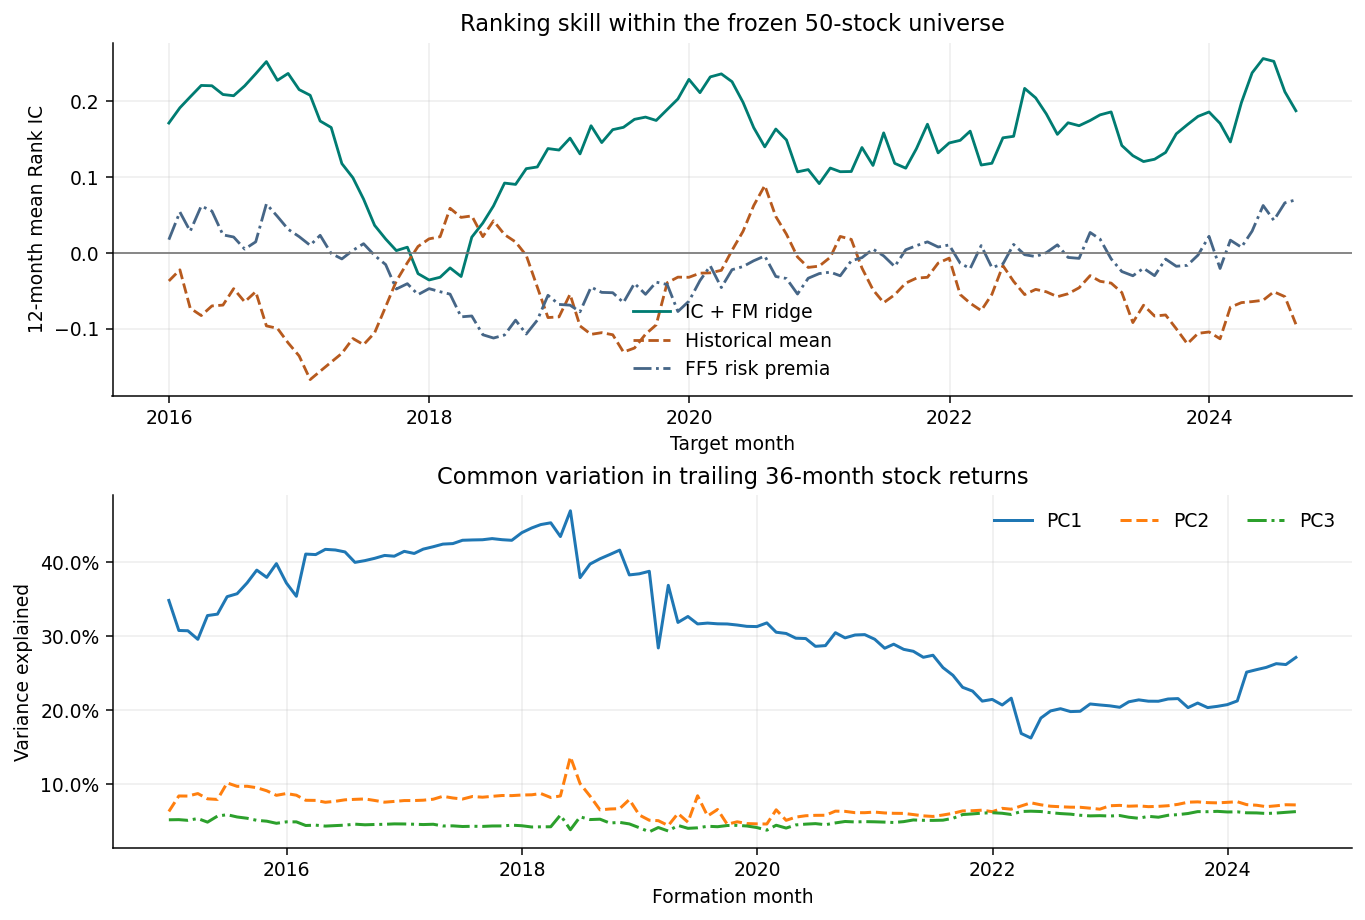

In [13]:
pca_frame = pd.DataFrame.from_dict(pca_records, orient="index", columns=["PC1", "PC2", "PC3"])
pca_frame.index = [month_end(month) for month in pca_frame.index]
fig, axes = plt.subplots(2, 1, figsize=(10, 6.7), layout="constrained")
model_ics = prediction_audit.pivot(index="Target_Date", columns="Model", values="Rank IC")
for name, color, style in [
    (MAIN, "#007C72", "-"), (HIST, "#B75A1E", "--"), (FF5, "#466687", "-."),
]:
    axes[0].plot(model_ics[name].rolling(12).mean(), label=name, color=color, linestyle=style)
axes[0].axhline(0, color="#777777", lw=0.9)
axes[0].set(title="Ranking skill within the frozen 50-stock universe",
            ylabel="12-month mean Rank IC", xlabel="Target month")
axes[0].legend(frameon=False)
for pc, style in zip(pca_frame.columns, styles):
    axes[1].plot(pca_frame[pc], label=pc, linestyle=style, lw=1.6)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set(title="Common variation in trailing 36-month stock returns",
            ylabel="Variance explained", xlabel="Formation month")
axes[1].legend(frameon=False, ncols=3)
for axis in axes:
    axis.xaxis.set_major_locator(mdates.YearLocator(2))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

### 如何解读结果

- **固定池和调权各自有贡献。** 固定池等权的净年化为 6.97%，模型权重为 15.07%，同池年化差 8.10 个百分点。相对固定池等权，模型的月均收益差为 +0.68 个百分点，6 个月时间块配对 95% 区间为 +0.30 至 +1.08 个百分点。
- **区分观察到的超额和推断的不确定性。** 模型相对中证 500 价格指数的月均差为 +1.55 个百分点，95% 区间为 +0.32 至 +2.90 个百分点。相对 FF5 广义市场代理的月均差为 +1.35 个百分点，95% 区间为 −0.05 至 +2.94 个百分点，跨过零。模型年化波动为 36.19%。
- **预测确实参与池内排序。** 同一固定池内，IC 增补模型的平均 Rank IC 为 0.1463，个股历史均值为 −0.0513。相对个股历史均值的 OOS R² 为 3.84%。
- **持仓层面的限制。** 平均每月双向成交额占净值 52.49%，按约定费率折合平均每月费用约 0.10%。平均冻结股票权重为 4.85%，期末无报价股票的仓位权重为 0.00%。回测依赖历史数据商的报价和收益覆盖，费用假设未建模市场冲击。

## 8. 导出三个文件

| 文件 | 具体内容与用法 |
|---|---|
| `P1_Candidate_Universe.csv` | **只有 50 行。** 每支记录 OOS 前的入池排名、初始预测、选股日和训练标签截止日。这是 50 支名单的唯一来源。 |
| `P1_Expected_Returns.csv` | **每月一行，固定 50 列。** `Date` 是调仓月的日历月末。列里是次月预期收益小数。不可评分时暂以历史截面均值作预测回退，实际下单状态保存在 notebook 的回测变量中。 |
| `Actual_Returns.csv` | **每月一行，同样的固定 50 列。** `Date` 是收益实现月的日历月末。用调仓月份加一个月对齐。例如 2014-12-31 的预测匹配 2015-01-31 的实现收益。 |

Part 2 用冻结名单对齐协方差矩阵的行列，并从原始历史收益按信号日截断。Part 3 读取固定 50 列的预期收益和实现收益，若要与本 notebook 的模拟成交口径一致，也需要使用逐日交易限制与现金规则。

In [14]:
expected_wide = pd.DataFrame(
    {month_end(formation): forecast[MAIN] for formation, forecast in fixed_forecasts.items()}
).T
expected_wide.index.name = "Date"
expected_wide = expected_wide.reindex(columns=fixed_universe)
actual_wide = returns.reindex(index=oos_months + 1, columns=fixed_universe)
actual_wide = actual_wide.set_axis(pd.DatetimeIndex(
    [month_end(month) for month in actual_wide.index], name="Date"
))

assert expected_wide.columns.equals(fixed_universe)
assert actual_wide.columns.equals(fixed_universe)
assert expected_wide.index.to_period("M").equals(oos_months)
assert (expected_wide.index.to_period("M") + 1).equals(actual_wide.index.to_period("M"))
assert np.allclose(expected_wide.iloc[0], locked_pool.Initial_Expected_Return)
assert locked_pool.Selection_Signal_Date.lt(locked_pool.OOS_Start_Close).all()
assert np.isfinite(expected_wide.to_numpy()).all()
assert len(locked_pool) == POOL_SIZE and locked_pool.Asset.nunique() == POOL_SIZE
assert not locked_pool.Asset.duplicated().any()

OUTPUT.mkdir(parents=True, exist_ok=True)
locked_pool.to_csv(OUTPUT / "P1_Candidate_Universe.csv", index=False)
expected_wide.to_csv(OUTPUT / "P1_Expected_Returns.csv")
actual_wide.to_csv(OUTPUT / "Actual_Returns.csv")

display(expected_wide.iloc[:3, :6].style.format("{:.2%}"))
print(f"Exported one fixed pool of {POOL_SIZE} stocks and {len(expected_wide)} OOS months.")

,300281.SZ,300069.SZ,600768.SH,600137.SH,300277.SZ,300354.SZ
Date,,,,,,
2014-12-31 00:00:00,4.66%,4.61%,4.60%,4.56%,4.49%,4.48%
2015-01-31 00:00:00,3.25%,3.95%,2.90%,3.60%,3.17%,2.43%
2015-02-28 00:00:00,2.42%,3.29%,3.08%,3.61%,3.21%,1.77%


Exported one fixed pool of 50 stocks and 116 OOS months.
